# Gradient boosting: LightGBM (issue #12)

Follows the shared evaluation protocol (`src/common.py`, issue #8): development data = train + val, repeated stratified 5-fold CV x 3, seed 42, test set untouched.

Tuned scores use **nested CV** (the hyper-parameter search runs only inside each outer training fold), so they are not inflated by tuning. Same method as `notebooks/boosting_sklearn.ipynb` (#10). Early stopping is not used (the shared `evaluate()` has no validation-set hook); `n_estimators` is tuned instead.

Needs LightGBM: `pip install lightgbm`. On macOS also `brew install libomp`.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import loguniform, randint, uniform
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score

from src.common import (load_dev, load_train_val, evaluate, get_cv, log_result, _who,
                        SCORING, RANDOM_STATE, ROOT)
warnings.filterwarnings('ignore')

X, y = load_dev()
# n_jobs=1 inside each model: folds already run in parallel, and this keeps fit times comparable
BASE = dict(random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
print(X.shape)

(16604, 6)


## 1. Default settings (logged)

In [2]:
default = evaluate(LGBMClassifier(**BASE), X, y, name='LightGBM', params={'defaults': True}, n_jobs=-1,
                   notes='fit time measured with n_jobs=1 per model')
cols = ['model', 'cv_auc_mean', 'cv_auc_std', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean', 'fit_time_mean_s']
pd.DataFrame([default])[cols]

,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,LightGBM,0.6896,0.0091,0.7907,0.755,0.8258,0.6955,0.068


## 2. Tuning with nested CV

`RandomizedSearchCV`, 25 settings, inner 3-fold CV on each outer training part, scored by ROC AUC.

In [3]:
SPACE = {'n_estimators': randint(100, 501), 'learning_rate': loguniform(0.01, 0.2),
         'num_leaves': randint(4, 64), 'min_child_samples': randint(10, 151),
         'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4),
         'reg_lambda': loguniform(1e-3, 10)}
N_ITER, INNER_CV = 25, StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def make_search(seed=RANDOM_STATE):
    est = LGBMClassifier(subsample_freq=1, **BASE)
    return RandomizedSearchCV(est, SPACE, n_iter=N_ITER, cv=INNER_CV, scoring='roc_auc',
                              random_state=seed, n_jobs=1, refit=True)

t = time.time()
res = cross_validate(make_search(), X, y, cv=get_cv(), scoring=SCORING, n_jobs=-1)
tuned = {'date': date.today().isoformat(), 'who': _who(), 'model': 'LightGBM tuned', 'features': 'raw',
         'params': f'RandomizedSearchCV n_iter={N_ITER}', 'n_rows': len(X),
         'fit_time_mean_s': round(float(np.mean(res['fit_time'])), 1),
         'notes': 'NESTED CV (search inside each outer training fold); fit time includes the search'}
for k in SCORING:
    tuned[f'cv_{k}_mean'] = round(float(np.mean(res[f'test_{k}'])), 4)
    tuned[f'cv_{k}_std'] = round(float(np.std(res[f'test_{k}'])), 4)
log_result(tuned)

best_search = make_search().fit(X, y)
best_params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in best_search.best_params_.items()}
(ROOT / 'results' / 'best_params_lightgbm.json').write_text(json.dumps(best_params, indent=2))
print(f'nested AUC {tuned["cv_auc_mean"]} +/- {tuned["cv_auc_std"]} ({time.time()-t:.0f}s)')
print('final params:', best_params)
pd.DataFrame([default, tuned])[cols]

nested AUC 0.7025 +/- 0.0088 (40s)
final params: {'colsample_bytree': 0.8428136990746738, 'learning_rate': 0.02286036785892037, 'min_child_samples': 24, 'n_estimators': 400, 'num_leaves': 4, 'reg_lambda': 0.0011549033124221243, 'subsample': 0.7693605922825478}


,model,cv_auc_mean,cv_auc_std,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,LightGBM,0.6896,0.0091,0.7907,0.7550,0.8258,0.6955,0.068
1,LightGBM tuned,0.7025,0.0088,0.7999,0.7616,0.8379,0.6980,20.600


## 3. Overfitting check

Train on the official `train` split, evaluate on `val` after each round (default learning rate).

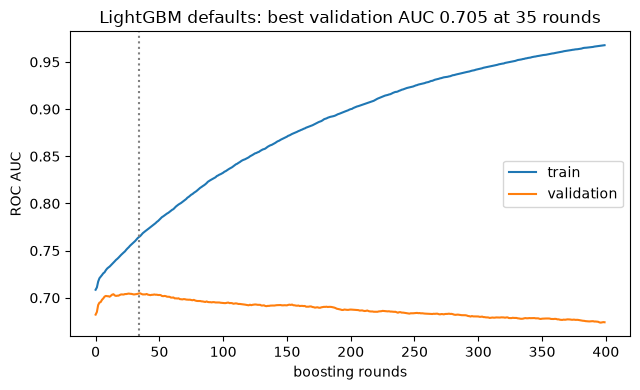

In [4]:
X_tr, y_tr, X_va, y_va = load_train_val()
m = LGBMClassifier(n_estimators=400, **BASE).fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)], eval_metric='auc')
ev = m.evals_result_
tr, va = ev['training']['auc'], ev['valid_1']['auc']
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tr, label='train'); ax.plot(va, label='validation')
ax.axvline(int(np.argmax(va)), ls=':', c='gray')
ax.set_title(f'LightGBM defaults: best validation AUC {max(va):.3f} at {int(np.argmax(va))+1} rounds')
ax.set_xlabel('boosting rounds'); ax.set_ylabel('ROC AUC'); ax.legend()
(ROOT / 'reports' / 'figures').mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / 'boosting_lightgbm_overfit.png', dpi=130); plt.show()

## 4. Feature importance (gain) of the tuned model

Fit on all dev data with the final parameters. Indicative only; permutation importance and SHAP are in #16.

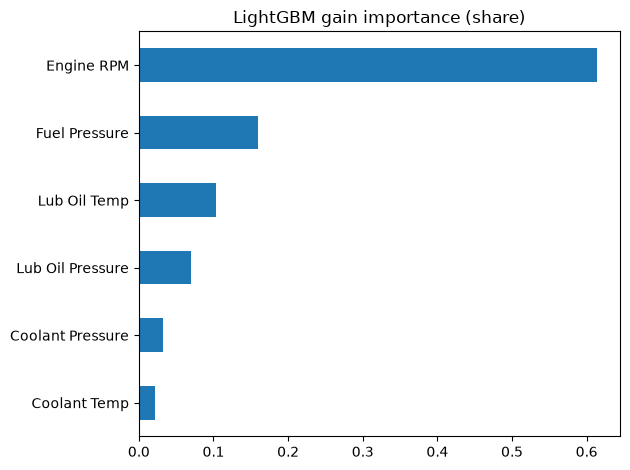

In [5]:
final = LGBMClassifier(subsample_freq=1, importance_type='gain', **BASE, **best_params).fit(X, y)
imp = pd.Series(final.feature_importances_, index=X.columns).sort_values()
(imp / imp.sum()).plot.barh(title='LightGBM gain importance (share)'); plt.tight_layout(); plt.show()